# Simulation : d'où vient la loi de Zipf ?

On simule des villes dont la taille croît à chaque période d'un taux aléatoire **indépendant de leur taille** (loi de Gibrat), avec une taille minimale en dessous de laquelle une ville ne descend pas. Gabaix (1999) a montré que la distribution des tailles converge alors vers une loi de Pareto, et que son exposant ζ est la solution de

$$\mathbb{E}\big[(1+\varepsilon)^{\zeta}\big] = 1 ,$$

où ε est le taux de croissance d'une période. Quand le taux de croissance moyen est nul (μ = 0), on a $\mathbb{E}[1+\varepsilon]=1$ : **ζ = 1, c'est la loi de Zipf**, quelle que soit la dispersion σ des taux de croissance.

Deux enseignements de la simulation, qui reviennent sur les données réelles : la convergence est très lente (elle prend de l'ordre de $1/\sigma^2$ périodes), et un échantillon tronqué aux plus grandes villes donne un exposant très variable.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from zipf_villes import (
    ajuste_mco,
    ajuste_pareto,
    exposant_pareto,
    exposant_theorique,
    simule_villes,
)

IMAGES = Path("../images")
SEED = 1235
N = 2000  # nombre de villes
SIGMA = 0.1  # écart-type du taux de croissance
SEUIL = 10_000  # taille minimale d'une ville

## Les trajectoires

Toutes les villes partent du seuil. À chaque période, chacune est multipliée par 1 + ε, avec ε de loi normale de moyenne 0 et d'écart-type σ = 0,1, puis ramenée au seuil si elle passe en dessous. On simule 3 000 périodes en une seule fois : les mêmes villes sont observées à différents instants.

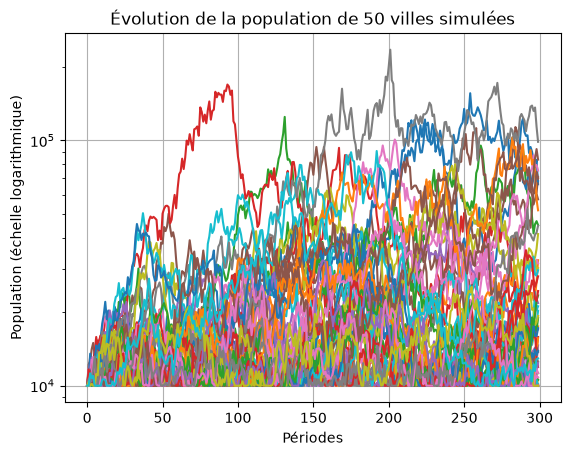

In [2]:
villes = simule_villes(N, periodes=3000, sigma=SIGMA, seuil=SEUIL, rng=SEED)

fig, ax = plt.subplots()
ax.plot(villes[:300, :50])
ax.set_yscale("log")
ax.set_xlabel("Périodes")
ax.set_ylabel("Population (échelle logarithmique)")
ax.set_title("Évolution de la population de 50 villes simulées")
ax.grid(True)
fig.savefig(IMAGES / "simulation_trajectoires.png", dpi=120, bbox_inches="tight")
plt.show()

## Le classement des villes à différents instants

Pour une loi de Zipf, le graphique du logarithme du rang en fonction du logarithme de la taille est une droite de pente −1. Voici les mêmes villes après 100, 500, 1 000 et 3 000 périodes.

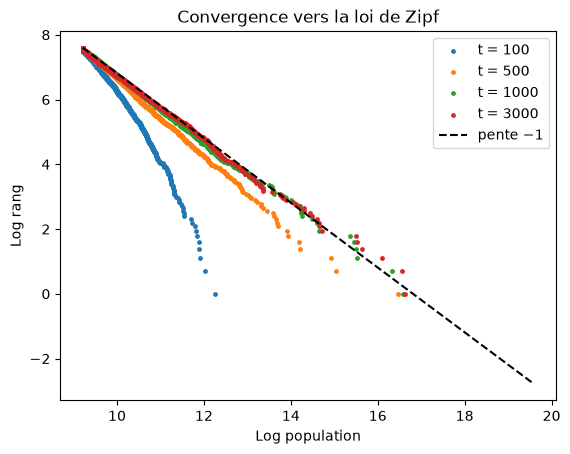

In [3]:
instants = (100, 500, 1000, 3000)

fig, ax = plt.subplots()
for t in instants:
    tailles = np.sort(villes[t - 1])[::-1]
    ax.scatter(np.log(tailles), np.log(np.arange(1, N + 1)), s=6, label=f"t = {t}")
x = np.log([SEUIL, villes.max()])
ax.plot(x, -(x - np.log(SEUIL)) + np.log(N), "k--", label="pente −1")
ax.set_xlabel("Log population")
ax.set_ylabel("Log rang")
ax.set_title("Convergence vers la loi de Zipf")
ax.legend()
fig.savefig(IMAGES / "simulation_convergence.png", dpi=120, bbox_inches="tight")
plt.show()

À 100 périodes la queue de la distribution est beaucoup trop fine, bien en dessous de la droite de pente −1 ; la distribution ne se stabilise qu'après quelques centaines de périodes. On mesure l'exposant avec les trois méthodes du package : la régression classique sur les 500 plus grandes villes, sa correction de Gabaix et Ibragimov, et le maximum de vraisemblance avec choix automatique du seuil.

In [4]:
lignes = []
for t in instants:
    tailles = villes[t - 1]
    pareto = ajuste_pareto(tailles)
    lignes.append(
        {
            "t": t,
            "régression (500 plus grandes)": ajuste_mco(tailles, n=500).exposant,
            "Gabaix-Ibragimov (500)": ajuste_mco(tailles, n=500, decalage=0.5).exposant,
            "maximum de vraisemblance": pareto.exposant,
            "seuil choisi": pareto.xmin,
            "villes au-dessus du seuil": pareto.n,
        }
    )
pd.DataFrame(lignes).set_index("t").round(2)

,régression (500 plus grandes),Gabaix-Ibragimov (500),maximum de vraisemblance,seuil choisi,villes au-dessus du seuil
t,,,,,
100,2.37,2.41,1.75,10768.42,1689
500,1.15,1.18,1.21,15648.64,1155
1000,0.99,1.01,1.04,12076.45,1585
3000,0.98,1.00,0.99,12871.92,1426


## Sensibilité à l'écart-type σ

Plus les taux de croissance sont dispersés, plus la distribution converge vite. Voici l'état des mêmes simulations après 100 puis 1 000 périodes, pour trois valeurs de σ. L'exposant limite théorique, donné par `exposant_theorique`, est en légende. Pour σ = 0,5 il est un peu inférieur à 1 : avec une dispersion aussi forte, certaines villes « perdraient plus de 100 % » en une période (ε < −1) et tombent directement sur le seuil.

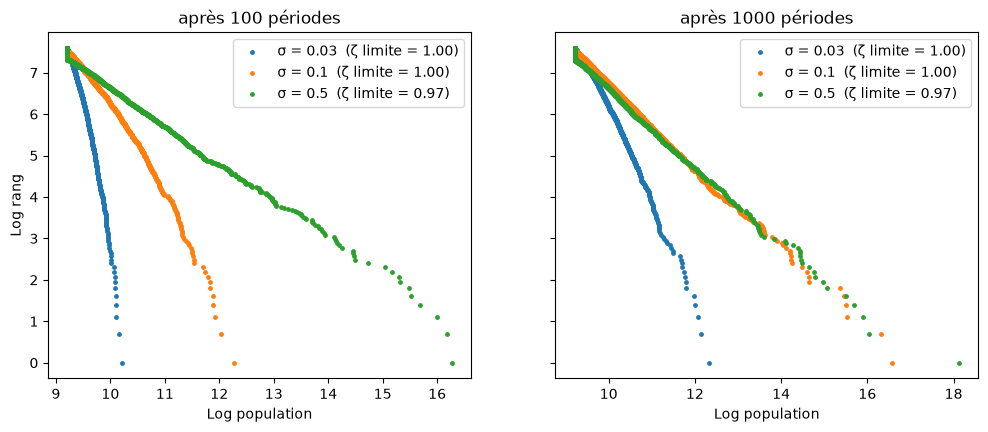

In [5]:
sigmas = (0.03, 0.1, 0.5)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, t in zip(axes, (100, 1000), strict=True):
    for sigma in sigmas:
        v = simule_villes(N, periodes=t, sigma=sigma, seuil=SEUIL, rng=SEED)[-1]
        tailles = np.sort(v)[::-1]
        zeta = exposant_theorique(0.0, sigma)
        ax.scatter(
            np.log(tailles),
            np.log(np.arange(1, N + 1)),
            s=6,
            label=f"σ = {sigma}  (ζ limite = {zeta:.2f})",
        )
    ax.set_title(f"après {t} périodes")
    ax.set_xlabel("Log population")
    ax.legend()
axes[0].set_ylabel("Log rang")
fig.savefig(IMAGES / "simulation_sigma.png", dpi=120, bbox_inches="tight")
plt.show()

## Combien de villes faut-il garder pour estimer l'exposant ?

On estime l'exposant sur la simulation convergée (t = 3 000, où ζ = 1 en théorie) en ne gardant que les n plus grandes villes. Dès que n dépasse quelques centaines, les trois méthodes sont proches de 1. Quand n est petit, elles divergent : avec n = 50 la régression classique donne 0,88, la correction de Gabaix et Ibragimov 0,95 et le maximum de vraisemblance 1,01. C'est le biais de petit échantillon de la régression, bien connu dans la littérature.

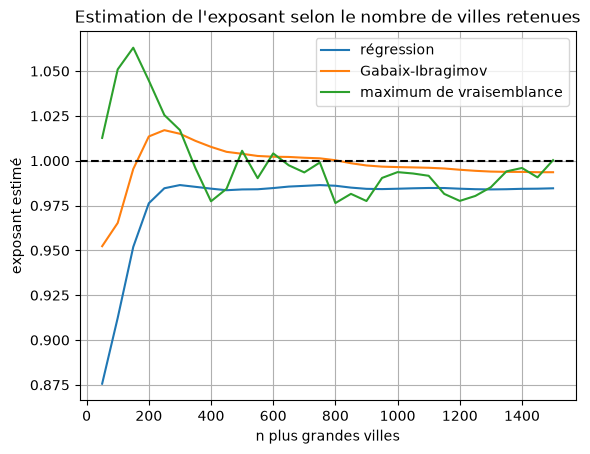

In [6]:
tailles = villes[-1]
ordonnees = np.sort(tailles)[::-1]
ns = np.arange(50, 1501, 50)
resultats = pd.DataFrame(
    {
        "régression": [ajuste_mco(tailles, n=n).exposant for n in ns],
        "Gabaix-Ibragimov": [
            ajuste_mco(tailles, n=n, decalage=0.5).exposant for n in ns
        ],
        "maximum de vraisemblance": [
            exposant_pareto(tailles, ordonnees[n - 1]).exposant for n in ns
        ],
    },
    index=ns,
)
fig, ax = plt.subplots()
resultats.plot(
    grid=True, xlabel="n plus grandes villes", ylabel="exposant estimé", ax=ax
)
ax.axhline(1.0, color="k", linestyle="--")
ax.set_title("Estimation de l'exposant selon le nombre de villes retenues")
fig.savefig(IMAGES / "simulation_estimateurs.png", dpi=120, bbox_inches="tight")
plt.show()

## À retenir

- Un processus de croissance proportionnelle avec une taille minimale suffit à produire la loi de Zipf, sans rien supposer d'autre sur les villes.
- Le temps de convergence est long : une loi de Zipf observée sur des données réelles ne dit pas que le régime stationnaire est atteint.
- Les estimations dépendent de la méthode et du nombre de villes retenues, surtout quand celui-ci est petit : la régression classique est la plus biaisée, la correction de Gabaix et Ibragimov et le maximum de vraisemblance le sont moins. Et tant que la distribution n'a pas convergé, aucune méthode ne retrouve l'exposant limite.